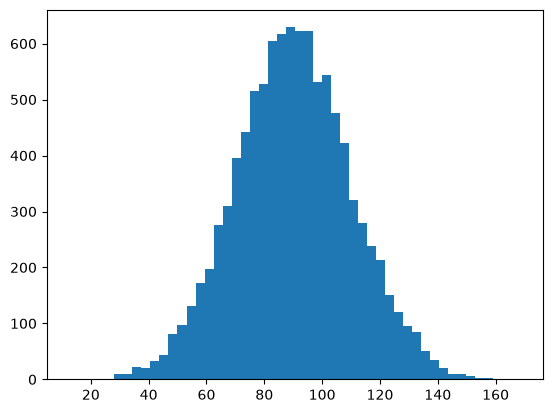

In [23]:
import numpy as np
import matplotlib.pyplot as plt
import copy, math
np.set_printoptions(precision=2)

income = np.random.normal(90, 20, 10000)

plt.hist(income, 50)
plt.show()

In [24]:
income.std()

np.float64(19.98254243336519)

In [25]:
income.var()

np.float64(399.3020021012404)

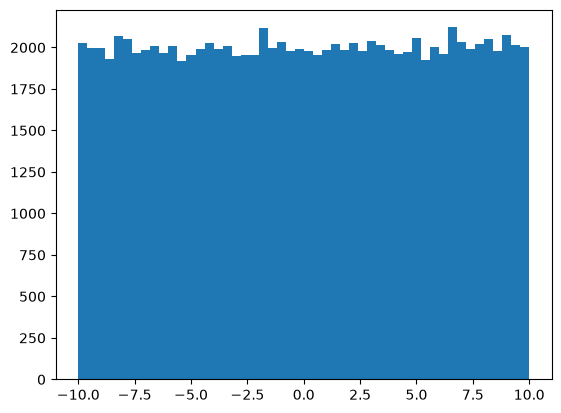

In [26]:
values = np.random.uniform(-10, 10, 100000)
plt.hist(values, 50)
plt.show()


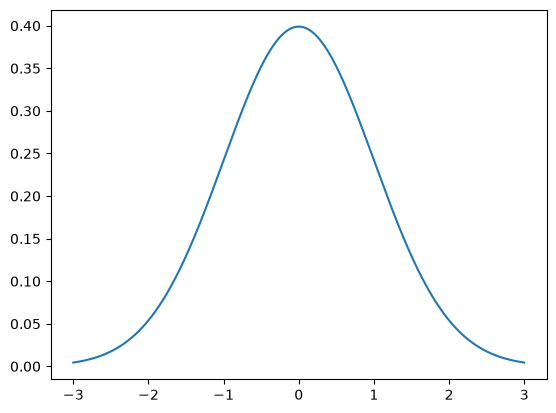

In [27]:
from scipy.stats import norm

x = np.arange(-3, 3, 0.001)
plt.plot(x, norm.pdf(x))


In [ ]:
# Cost function with multiple input

In [15]:
X_train = np.array([[2104, 5, 1, 45], [1416, 3, 2, 40], [852, 2, 1, 35]])
y_train = np.array([460, 232, 178])

In [16]:
b_init = 785.1811367994083
w_init = np.array([ 0.39133535, 18.75376741, -53.36032453, -26.42131618])

In [18]:
def predict_single_loop(x, w, b):
    n = x.shape[0]
    p = 0
    for i in range(n):
        p_i = x[i] * w[i]
        p = p + p_i
    p = p + b
    return p


In [19]:
#get a row from training data
x_vec = X_train[0,:]
f_wb = predict_single_loop(x_vec, w_init, b_init)
print(f_wb)

459.9999976194083


In [21]:
# with vectorization

def predict(x, w, b):
    p = np.dot(x, w) + b
    return p

In [28]:
f_wb = predict(x_vec, w_init, b_init)
print(f_wb)

459.9999976194083


In [29]:
def compute_cost(X, y, w, b):

    m = X.shape[0]
    cost = 0
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost = cost + (f_wb_i - y[i])**2
    cost = cost / (2 * m)
    return cost

In [30]:
cost = compute_cost(X_train, y_train, w_init, b_init)
print(cost)

1.5578904045996674e-12


In [31]:
# Gradient with multiple variables
def compute_gradient(X, y, w, b):

    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0

    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]    
        dj_db = dj_db + err                        
    dj_dw = dj_dw / m                                
    dj_db = dj_db / m                                
        
    return dj_db, dj_dw



In [32]:
tmp_dj_db, tmp_dj_dw = compute_gradient(X_train, y_train, w_init, b_init)
print(tmp_dj_db, tmp_dj_dw)

-1.6739251122999121e-06 [-2.73e-03 -6.27e-06 -2.22e-06 -6.92e-05]


In [34]:
#Gradient with multiple variable
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 
    J_history = []
    w = copy.deepcopy(w_in)  #avoid modifying global w within function
    b = b_in
    
    for i in range(num_iters):

        # Calculate the gradient and update the parameters
        dj_db,dj_dw = gradient_function(X, y, w, b)   

        # Update Parameters using w, b, alpha and gradient
        w = w - alpha * dj_dw               
        b = b - alpha * dj_db               
      
        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            J_history.append( cost_function(X, y, w, b))

        # Print cost every at intervals 10 times or as many iterations if < 10
        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}   ")
        
    return w, b, J_history #return final w,b and J history for graphing



In [35]:
# initialize parameters
initial_w = np.zeros_like(w_init)
initial_b = 0.
# some gradient descent settings
iterations = 1000
alpha = 5.0e-7
# run gradient descent 
w_final, b_final, J_hist = gradient_descent(X_train, y_train, initial_w, initial_b,
                                                    compute_cost, compute_gradient, 
                                                    alpha, iterations)
print(f"b,w found by gradient descent: {b_final:0.2f},{w_final} ")
m,_ = X_train.shape
for i in range(m):
    print(f"prediction: {np.dot(X_train[i], w_final) + b_final:0.2f}, target value: {y_train[i]}")

Iteration    0: Cost  2529.46   
Iteration  100: Cost   695.99   
Iteration  200: Cost   694.92   
Iteration  300: Cost   693.86   
Iteration  400: Cost   692.81   
Iteration  500: Cost   691.77   
Iteration  600: Cost   690.73   
Iteration  700: Cost   689.71   
Iteration  800: Cost   688.70   
Iteration  900: Cost   687.69   
b,w found by gradient descent: -0.00,[ 0.2   0.   -0.01 -0.07] 
prediction: 426.19, target value: 460
prediction: 286.17, target value: 232
prediction: 171.47, target value: 178
